Install Libraries

In [1]:
!pip install -q imbalanced-learn openpyxl joblib

Import Libraries

In [3]:
import os
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [4]:
os.makedirs("outputs/plots", exist_ok=True)

print("Output folders created.")

Output folders created.


In [ ]:
# ============================================================
# CELL 2 — CREATE PROJECT STRUCTURE
# ============================================================

PROJECT_DIR = Path("/content/ml_capstone")

FOLDERS = [
    "data",
    "models",
    "results",
    "plots",
    "notebooks",
    "metadata"
]

for folder in FOLDERS:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project folder created:")
print(PROJECT_DIR)

In [5]:
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

print("Uploaded:", file_name)

Saving onlinefraud.csv to onlinefraud.csv
Uploaded: onlinefraud.csv


In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("File:", file_name)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: onlinefraud.csv
Shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [7]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (6362620, 11)

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate rows: 0


In [8]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,6362620.0,NaN,NaN,NaN,243.397246,142.331971,1.0,156.0,239.0,335.0,743.0
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,6362620.0,NaN,NaN,NaN,179861.903549,603858.231463,0.0,13389.57,74871.94,208721.4775,92445516.64
nameOrig,6362620,6353307,C1530544995,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,6362620.0,NaN,NaN,NaN,833883.104074,2888242.673007,0.0,0.0,14208.0,107315.175,59585040.37
newbalanceOrig,6362620.0,NaN,NaN,NaN,855113.668579,2924048.502971,0.0,0.0,0.0,144258.41,49585040.37
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,6362620.0,NaN,NaN,NaN,1100701.66652,3399180.112969,0.0,0.0,132705.665,943036.7075,356015889.35
newbalanceDest,6362620.0,NaN,NaN,NaN,1224996.398202,3674128.942094,0.0,0.0,214661.44,1111909.25,356179278.92
isFraud,6362620.0,NaN,NaN,NaN,0.001291,0.035905,0.0,0.0,0.0,0.0,1.0


In [9]:
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

print("\nConstant columns:")
print([c for c in df.columns if df[c].nunique() == 1])

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicates: 0

Constant columns:
[]


In [10]:
print("Unique nameOrig:", df["nameOrig"].nunique())
print("Unique nameDest:", df["nameDest"].nunique())

print("\nnameDest prefix:")
print(df["nameDest"].str[0].value_counts())

print("\nFraud by destination prefix:")
print(df.groupby(df["nameDest"].str[0])["isFraud"].sum())

print(
    "\nisFlaggedFraud=1 & isFraud=1:",
    ((df["isFlaggedFraud"] == 1) & (df["isFraud"] == 1)).sum()
)

print("Total isFlaggedFraud:", df["isFlaggedFraud"].sum())

print("Negative amounts:", (df["amount"] < 0).sum())
print("Zero amounts:", (df["amount"] == 0).sum())

Unique nameOrig: 6353307
Unique nameDest: 2722362

nameDest prefix:
nameDest
C    4211125
M    2151495
Name: count, dtype: int64

Fraud by destination prefix:
nameDest
C    8213
M       0
Name: isFraud, dtype: int64

isFlaggedFraud=1 & isFraud=1: 16
Total isFlaggedFraud: 16
Negative amounts: 0
Zero amounts: 16


In [11]:
print("Unique nameOrig:", df["nameOrig"].nunique())
print("Unique nameDest:", df["nameDest"].nunique())

print("\nnameDest prefix:")
print(df["nameDest"].str[0].value_counts())

print("\nFraud by destination prefix:")
print(df.groupby(df["nameDest"].str[0])["isFraud"].sum())

print(
    "\nisFlaggedFraud=1 & isFraud=1:",
    ((df["isFlaggedFraud"] == 1) & (df["isFraud"] == 1)).sum()
)

print("Total isFlaggedFraud:", df["isFlaggedFraud"].sum())

print("Negative amounts:", (df["amount"] < 0).sum())
print("Zero amounts:", (df["amount"] == 0).sum())

Unique nameOrig: 6353307
Unique nameDest: 2722362

nameDest prefix:
nameDest
C    4211125
M    2151495
Name: count, dtype: int64

Fraud by destination prefix:
nameDest
C    8213
M       0
Name: isFraud, dtype: int64

isFlaggedFraud=1 & isFraud=1: 16
Total isFlaggedFraud: 16
Negative amounts: 0
Zero amounts: 16


In [12]:
print("Unique nameOrig:", df["nameOrig"].nunique())
print("Unique nameDest:", df["nameDest"].nunique())

print("\nnameDest prefix:")
print(df["nameDest"].str[0].value_counts())

print("\nFraud by destination prefix:")
print(df.groupby(df["nameDest"].str[0])["isFraud"].sum())

print(
    "\nisFlaggedFraud=1 & isFraud=1:",
    ((df["isFlaggedFraud"] == 1) & (df["isFraud"] == 1)).sum()
)

print("Total isFlaggedFraud:", df["isFlaggedFraud"].sum())

print("Negative amounts:", (df["amount"] < 0).sum())
print("Zero amounts:", (df["amount"] == 0).sum())

Unique nameOrig: 6353307
Unique nameDest: 2722362

nameDest prefix:
nameDest
C    4211125
M    2151495
Name: count, dtype: int64

Fraud by destination prefix:
nameDest
C    8213
M       0
Name: isFraud, dtype: int64

isFlaggedFraud=1 & isFraud=1: 16
Total isFlaggedFraud: 16
Negative amounts: 0
Zero amounts: 16


In [13]:
vc = df["isFraud"].value_counts()
pct = vc / len(df) * 100

print(vc)
print()
print(pct)

isFraud
0    6354407
1       8213
Name: count, dtype: int64

isFraud
0    99.870918
1     0.129082
Name: count, dtype: float64


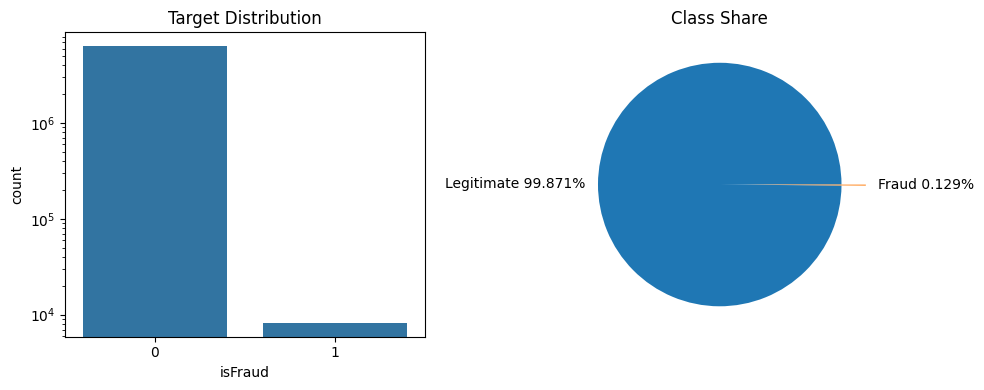

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x="isFraud", data=df, ax=ax[0])
ax[0].set_title("Target Distribution")
ax[0].set_yscale("log")

ax[1].pie(
    vc.values,
    labels=[
        f"Legitimate {pct[0]:.3f}%",
        f"Fraud {pct[1]:.3f}%"
    ],
    explode=[0, 0.2]
)
ax[1].set_title("Class Share")

plt.tight_layout()
plt.show()

In [15]:
t = df.groupby("type")["isFraud"].agg(["count", "sum"])
t["rate_%"] = t["sum"] / t["count"] * 100

display(t)

,count,sum,rate_%
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.183955
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.768799


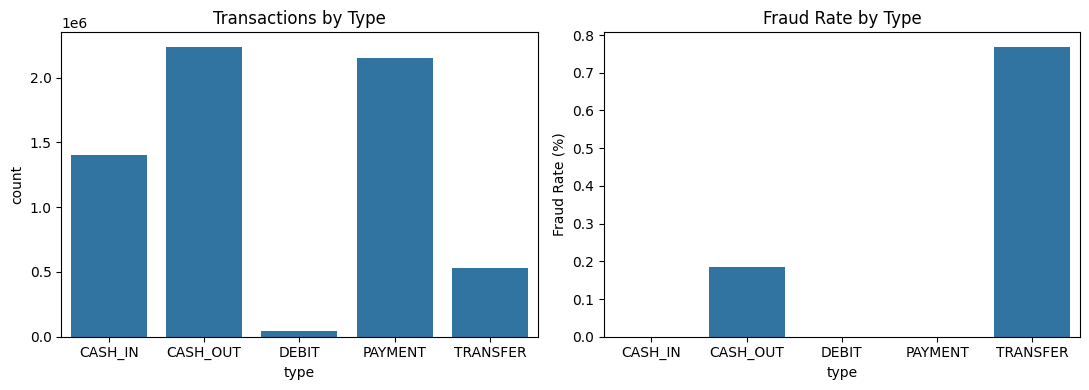

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(
    x="type",
    data=df,
    order=t.index,
    ax=ax[0]
)
ax[0].set_title("Transactions by Type")

sns.barplot(
    x=t.index,
    y=t["rate_%"],
    ax=ax[1]
)
ax[1].set_title("Fraud Rate by Type")
ax[1].set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [17]:
fraud_df = df[df["isFraud"] == 1]

legit_sample = df[
    df["isFraud"] == 0
].sample(
    n=min(200000, (df["isFraud"] == 0).sum()),
    random_state=42
)

sample_df = pd.concat([fraud_df, legit_sample])

print(
    sample_df.groupby("isFraud")["amount"].describe()
)

            count          mean           std   min        25%         50%  \
isFraud                                                                      
0        200000.0  1.802284e+05  6.133111e+05  0.41   13337.00   74856.325   
1          8213.0  1.467967e+06  2.404253e+06  0.00  127091.33  441423.440   

                 75%         max  
isFraud                           
0         208995.335  69886731.3  
1        1517771.480  10000000.0  


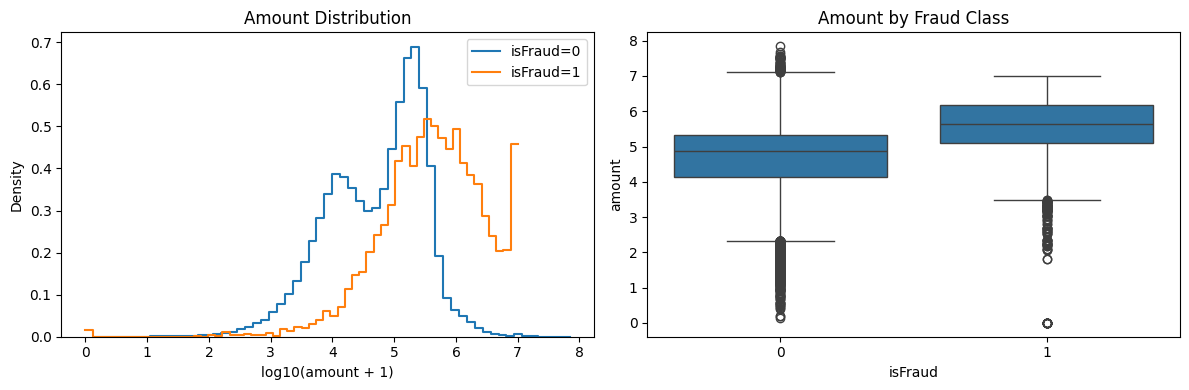

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for k, g in sample_df.groupby("isFraud"):
    sns.histplot(
        np.log10(g["amount"] + 1),
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=f"isFraud={k}",
        ax=ax[0]
    )

ax[0].legend()
ax[0].set_xlabel("log10(amount + 1)")
ax[0].set_title("Amount Distribution")

sns.boxplot(
    x="isFraud",
    y=np.log10(sample_df["amount"] + 1),
    data=sample_df,
    ax=ax[1]
)

ax[1].set_title("Amount by Fraud Class")

plt.tight_layout()
plt.show()

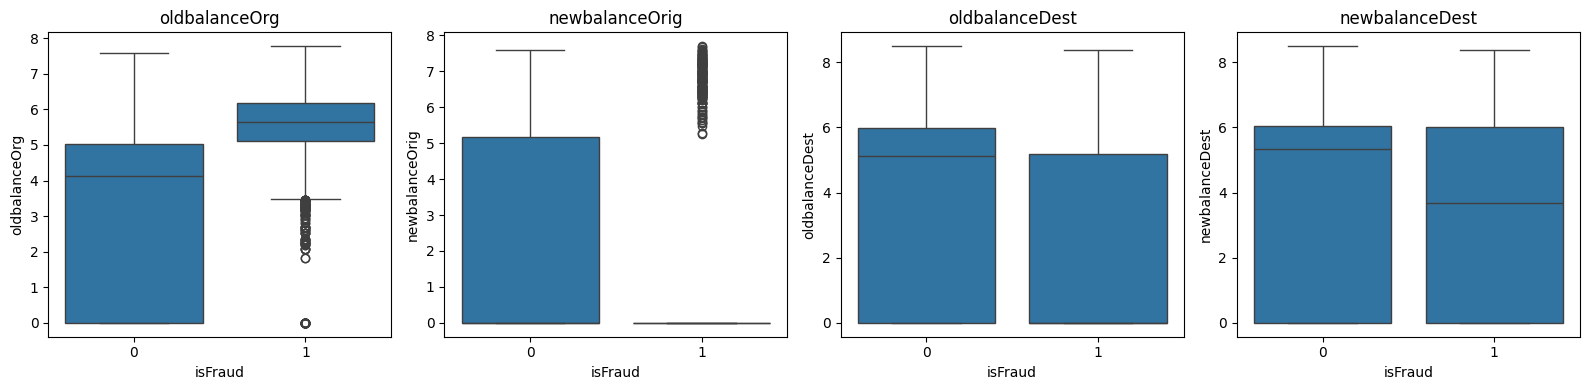

In [19]:
balance_cols = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for a, c in zip(ax, balance_cols):
    sns.boxplot(
        x="isFraud",
        y=np.log10(sample_df[c] + 1),
        data=sample_df,
        ax=a
    )
    a.set_title(c)

plt.tight_layout()
plt.show()

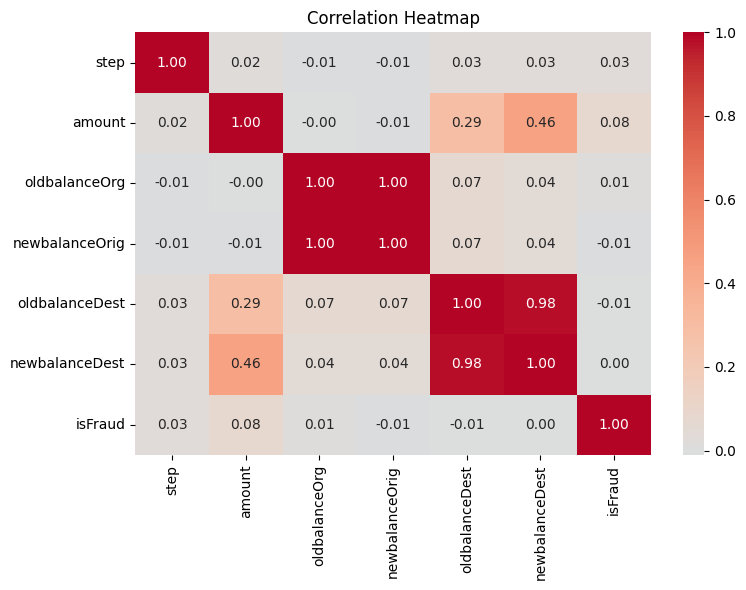

isFraud           1.000000
amount            0.076688
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64


In [20]:
corr_cols = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud"
]

corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print(
    corr["isFraud"]
    .sort_values(ascending=False)
)

In [21]:
df["hour"] = df["step"] % 24
df["day"] = df["step"] // 24

hour_stats = df.groupby("hour")["isFraud"].agg(
    ["count", "sum"]
)

hour_stats["rate"] = (
    hour_stats["sum"] /
    hour_stats["count"] * 100
)

day_stats = df.groupby("day")["isFraud"].agg(
    ["count", "sum"]
)

display(hour_stats)

,count,sum,rate
hour,,,
0,71587,300,0.419071
1,27111,358,1.320497
2,9018,372,4.125083
3,2007,326,16.243149
4,1241,274,22.078969
5,1641,366,22.303473
6,3420,358,10.467836
7,8988,328,3.649310
8,26915,368,1.367267


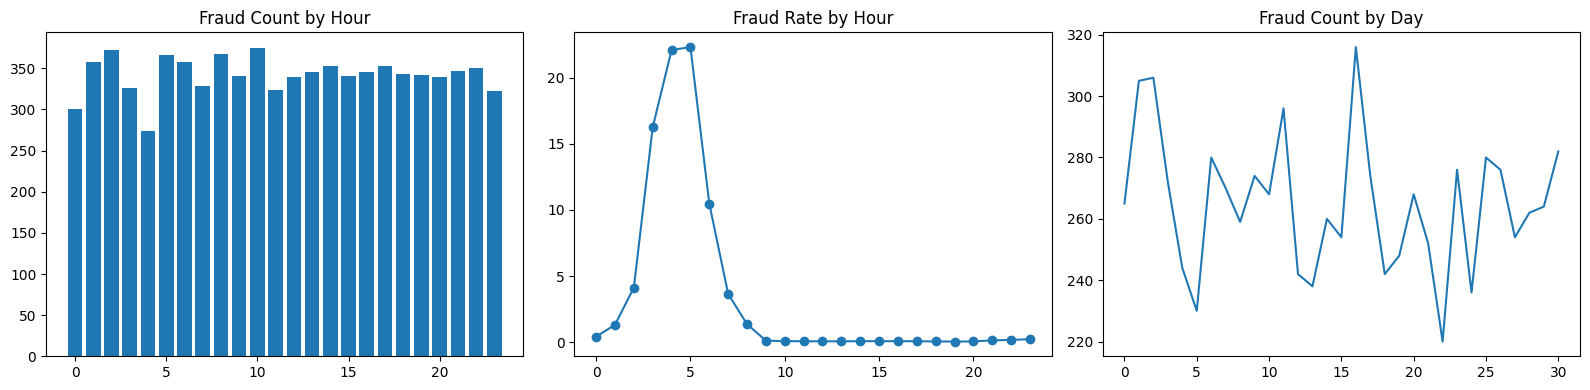

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].bar(
    hour_stats.index,
    hour_stats["sum"]
)
ax[0].set_title("Fraud Count by Hour")

ax[1].plot(
    hour_stats.index,
    hour_stats["rate"],
    marker="o"
)
ax[1].set_title("Fraud Rate by Hour")

ax[2].plot(
    day_stats.index,
    day_stats["sum"]
)
ax[2].set_title("Fraud Count by Day")

plt.tight_layout()
plt.show()

In [23]:
f = df[df["isFraud"] == 1]
l = df[df["isFraud"] == 0]

print(
    "Fraud: newbalanceOrig == 0:",
    (f["newbalanceOrig"] == 0).mean()
)

print(
    "Fraud: amount == oldbalanceOrg:",
    np.isclose(
        f["amount"],
        f["oldbalanceOrg"]
    ).mean()
)

print(
    "Fraud: oldbalanceDest == 0:",
    (f["oldbalanceDest"] == 0).mean()
)

print(
    "Legit: newbalanceOrig == 0:",
    (l["newbalanceOrig"] == 0).mean()
)

print(
    "Legit: oldbalanceDest == 0:",
    (l["oldbalanceDest"] == 0).mean()
)

print("Max legitimate amount:", l["amount"].max())
print("Max fraud amount:", f["amount"].max())

Fraud: newbalanceOrig == 0: 0.9805186898818946
Fraud: amount == oldbalanceOrg: 0.9782052843053696
Fraud: oldbalanceDest == 0: 0.6515280652623889
Legit: newbalanceOrig == 0: 0.566774051457516
Legit: oldbalanceDest == 0: 0.4247504133745289
Max legitimate amount: 92445516.64
Max fraud amount: 10000000.0


In [25]:
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone

print("Scikit-learn base classes imported successfully.")

Scikit-learn base classes imported successfully.


In [26]:
class FraudFeatureEngineer(
    BaseEstimator,
    TransformerMixin
):

    def __init__(self, use_post_balances=True):
        self.use_post_balances = use_post_balances

    def fit(self, X, y=None):
        required = [
            "step",
            "type",
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "oldbalanceDest",
            "newbalanceDest",
            "nameDest"
        ]

        missing = [
            c for c in required
            if c not in X.columns
        ]

        if missing:
            raise ValueError(
                f"Missing columns: {missing}"
            )

        return self

    def transform(self, X):

        d = pd.DataFrame(index=X.index)

        amt = X["amount"].astype(float)

        d["step"] = X["step"].astype(float)
        d["amount"] = amt

        d["oldbalanceOrg"] = (
            X["oldbalanceOrg"].astype(float)
        )

        d["newbalanceOrig"] = (
            X["newbalanceOrig"].astype(float)
        )

        d["oldbalanceDest"] = (
            X["oldbalanceDest"].astype(float)
        )

        d["newbalanceDest"] = (
            X["newbalanceDest"].astype(float)
        )

        d["hour"] = (
            X["step"] % 24
        ).astype(float)

        d["day"] = (
            X["step"] // 24
        ).astype(float)

        d["errorBalanceOrig"] = (
            d["newbalanceOrig"]
            + amt
            - d["oldbalanceOrg"]
        )

        d["errorBalanceDest"] = (
            d["oldbalanceDest"]
            + amt
            - d["newbalanceDest"]
        )

        d["orig_emptied"] = (
            d["newbalanceOrig"] == 0
        ).astype(float)

        d["dest_is_merchant"] = (
            X["nameDest"]
            .astype(str)
            .str.startswith("M")
        ).astype(float)

        d["dest_balance_zero_before"] = (
            d["oldbalanceDest"] == 0
        ).astype(float)

        d["amount_to_orig_balance"] = (
            amt /
            (d["oldbalanceOrg"] + 1)
        )

        d["log_amount"] = np.log1p(amt)

        d["type"] = X["type"].astype(str)

        return d

In [27]:
RAW_FEATURES = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "nameDest"
]

X = df[RAW_FEATURES].copy()
y = df["isFraud"].astype(int)

print(X.shape)
print(y.shape)

(6362620, 8)
(6362620,)


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("\nTrain:")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Train: (5090096, 8)
Test : (1272524, 8)

Train:
isFraud
0    5083526
1       6570
Name: count, dtype: int64

Test:
isFraud
0    1270881
1       1643
Name: count, dtype: int64


In [29]:
numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "hour",
    "day",
    "errorBalanceOrig",
    "errorBalanceDest",
    "orig_emptied",
    "dest_is_merchant",
    "dest_balance_zero_before",
    "amount_to_orig_balance",
    "log_amount"
]

categorical_features = ["type"]

In [30]:
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [35]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=300,
            class_weight="balanced",
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42
        )
}

In [36]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        (
            "features",
            FraudFeatureEngineer()
        ),
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            model
        )
    ])

print("Pipelines created:")
print(*pipelines.keys(), sep="\n")

Pipelines created:
Logistic Regression
Decision Tree
Random Forest


In [37]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=300,
            class_weight="balanced",
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42
        )
}

In [39]:
results_df = pd.DataFrame(results)

if "Model" not in results_df.columns:
    results_df = results_df.T.reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_sec
0,Logistic Regression,0.969817,0.039965,0.972002,0.076773,0.996082,0.618256,73.564787
1,Decision Tree,0.999850,0.896721,0.998783,0.945004,0.999391,0.998715,164.617140
2,Random Forest,0.999997,1.000000,0.997565,0.998781,0.999586,0.998713,1232.888571


In [40]:
results_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

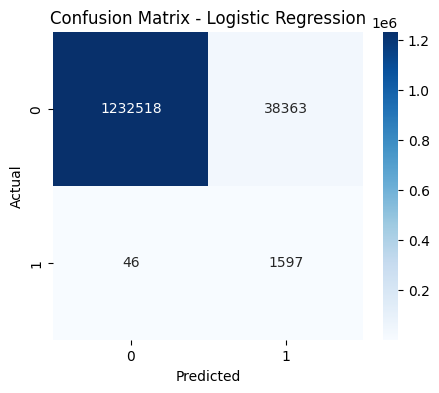

              precision    recall  f1-score   support

           0     1.0000    0.9698    0.9847   1270881
           1     0.0400    0.9720    0.0768      1643

    accuracy                         0.9698   1272524
   macro avg     0.5200    0.9709    0.5307   1272524
weighted avg     0.9987    0.9698    0.9835   1272524



In [41]:
best_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_name]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")

plt.show()

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

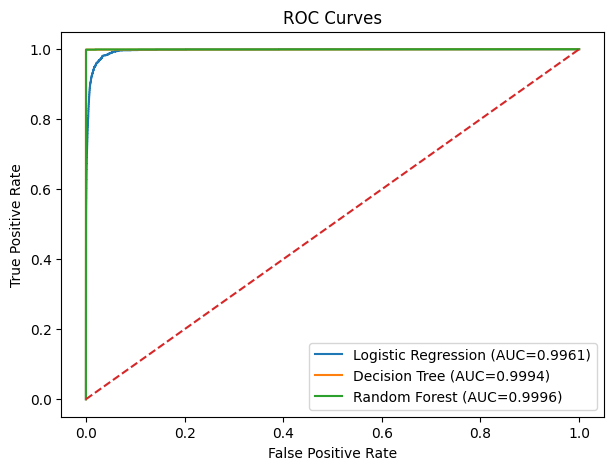

In [42]:
plt.figure(figsize=(7, 5))

for name, model in trained_models.items():

    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

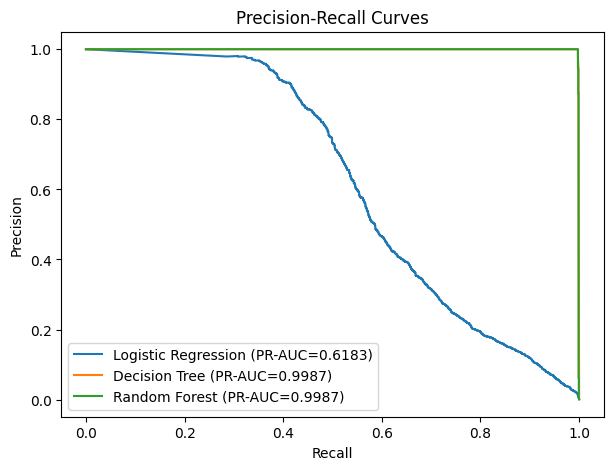

In [43]:
plt.figure(figsize=(7, 5))

for name, model in trained_models.items():

    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (PR-AUC={pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

In [44]:
BEST_MODEL_PATH = "/content/best_model.pkl"

joblib.dump(
    best_model,
    BEST_MODEL_PATH
)

print(
    "Saved:",
    BEST_MODEL_PATH
)

Saved: /content/best_model.pkl


In [45]:
loaded_model = joblib.load(
    BEST_MODEL_PATH
)

loaded_pred = loaded_model.predict(
    X_test
)

print(
    "Predictions identical:",
    np.array_equal(
        y_pred,
        loaded_pred
    )
)

Predictions identical: True


In [46]:
best_row = results_df.iloc[0].to_dict()

with open(
    "/content/metrics.json",
    "w"
) as f:

    json.dump(
        best_row,
        f,
        indent=4
    )

print(json.dumps(best_row, indent=4))

{
    "Model": "Logistic Regression",
    "Accuracy": 0.9698166792924927,
    "Precision": 0.03996496496496497,
    "Recall": 0.9720024345709068,
    "F1": 0.07677330961709491,
    "ROC_AUC": 0.9960823008625955,
    "PR_AUC": 0.6182556818379676,
    "Training_Time_sec": 73.56478667259216
}
